In [12]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt


In [10]:
!pip install opacus


In [11]:
from opacus import PrivacyEngine
from opacus.validators import ModuleValidator

In [13]:

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_full = torchvision.datasets.MNIST(root='./data', train=True, transform=transform, download=True)
test_set = torchvision.datasets.MNIST(root='./data', train=False, transform=transform, download=True)

100%|██████████| 9.91M/9.91M [00:00<00:00, 14.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 361kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.26MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.30MB/s]


In [15]:
### TASK -1 GroupNorm CNN built; non-private baseline trained and tested
train_set = Subset(train_full, range(20000))

batch_size = 256
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False)

In [17]:
train_loader

In [18]:
test_loader

In [16]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.GroupNorm(4, 32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.GroupNorm(8, 64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(7*7*64, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )
    def forward(self, x):
        return self.model(x)
# Validate that the model is compatible with Opacus
ModuleValidator.fix(SmallCNN())

SmallCNN(
  (model): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): GroupNorm(4, 32, eps=1e-05, affine=True, bias=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): GroupNorm(8, 64, eps=1e-05, affine=True, bias=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Flatten(start_dim=1, end_dim=-1)
    (9): Linear(in_features=3136, out_features=128, bias=True)
    (10): ReLU()
    (11): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [22]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def train(model, train_loader, optimizer, criterion, device, epochs=3):
    model.train()
    for epoch in range(epochs):
        for data, target in train_loader:
            data, target = data.to(device), target.to(device)
            optimizer.zero_grad()
            output = model(data)
            loss = criterion(output, target)
            loss.backward()
            optimizer.step()

def test(model, test_loader, device):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            outputs = model(data)
            _, predicted = outputs.max(1)
            correct += (predicted == target).sum().item()
            total += target.size(0)
    acc = 100.0 * correct / total
    return acc

In [23]:
# Define device if not already defined
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Baseline model (no DP)
baseline = SmallCNN().to(device)
lr = 0.01
optimizer = optim.SGD(baseline.parameters(), lr=lr, momentum=0.9)
criterion = nn.CrossEntropyLoss()

train(baseline, train_loader, optimizer, criterion, device)
baseline_acc = test(baseline, test_loader, device)
print(f'Baseline (no DP) test accuracy: {baseline_acc:.2f} %')

Baseline (no DP) test accuracy: 98.16 %


In [33]:
### TASK - 2 DP models trained with Opacus for ε = 10, 5, 1; accuracy reported

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def train_dp_model(epsilon_target, delta=1e-5, max_grad_norm=1.0):
    model = SmallCNN().to(device)
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    criterion = nn.CrossEntropyLoss()
    privacy_engine = PrivacyEngine()
    model, optimizer, train_loader_dp = privacy_engine.make_private_with_epsilon(
        module=model,
        optimizer=optimizer,
        data_loader=train_loader,
        epochs=3,
        target_epsilon=epsilon_target,
        target_delta=delta,
        max_grad_norm=max_grad_norm,
    )
    train(model, train_loader_dp, optimizer, criterion, device)
    test_acc = test(model, test_loader, device)
    return test_acc, privacy_engine.get_epsilon(delta)

epsilons = [10.0, 5.0, 1.0]
dp_accuracies = []
for eps in epsilons:
    acc, eps_spent = train_dp_model(eps)
    dp_accuracies.append((eps, acc, eps_spent))
    print(f'DP Model eps={eps}: test accuracy = {acc:.2f} % | eps spent = {eps_spent:.2f}')

/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/opacus/accountants/analysis/rdp.py:332: UserWarning: Optimal order is the largest alpha. Please consider expanding the range of alphas to get a tighter privacy bound.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


DP Model eps=10.0: test accuracy = 87.12 % | eps spent = 9.99
DP Model eps=5.0: test accuracy = 87.08 % | eps spent = 5.00
DP Model eps=1.0: test accuracy = 86.42 % | eps spent = 1.00


In [34]:

### TASK - 3 Fixed noise_multiplier run; ε recorded after each epoch

noise_multiplier = 1.1
delta = 1e-5
max_grad_norm = 1.0
model_n1 = SmallCNN().to(device)
optimizer_n1 = optim.SGD(model_n1.parameters(), lr=lr, momentum=0.9)
criterion = nn.CrossEntropyLoss()
privacy_engine = PrivacyEngine()
model_n1, optimizer_n1, train_loader_n1 = privacy_engine.make_private(
    module=model_n1,
    optimizer=optimizer_n1,
    data_loader=train_loader,
    noise_multiplier=noise_multiplier,
    max_grad_norm=max_grad_norm,
)

eps_per_epoch = []
for epoch in range(3):
    model_n1.train()
    for data, target in train_loader_n1:
        data, target = data.to(device), target.to(device)
        optimizer_n1.zero_grad()
        outputs = model_n1(data)
        loss = criterion(outputs, target)
        loss.backward()
        optimizer_n1.step()
    epsilon = privacy_engine.get_epsilon(delta)
    eps_per_epoch.append(epsilon)
    print(f'Epoch {epoch+1}, epsilon spent: {epsilon:.2f}')

Epoch 1, epsilon spent: 0.66
Epoch 2, epsilon spent: 0.85
Epoch 3, epsilon spent: 1.01


In [35]:
### TASK - 4 Membership-inference confidence check for baseline and ε = 1

def get_max_softmax(model, data_loader):
    model.eval()
    max_conf = []
    with torch.no_grad():
        for data, _ in data_loader:
            output = model(data.to(device))
            conf = torch.softmax(output, dim=1).max(1)[0].cpu().numpy()
            max_conf.append(conf)
    return np.concatenate(max_conf)

# Baseline confidence
t_train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=False)
baseline_train_conf = get_max_softmax(baseline, t_train_loader)
baseline_test_conf = get_max_softmax(baseline, test_loader)
baseline_gap = baseline_train_conf.mean() - baseline_test_conf.mean()

# DP model (epsilon=1)
dp_model_eps1 = SmallCNN().to(device)
optimizer = optim.SGD(dp_model_eps1.parameters(), lr=lr, momentum=0.9)
criterion = nn.CrossEntropyLoss()
privacy_engine = PrivacyEngine()
dp_model_eps1, optimizer, train_loader_eps1 = privacy_engine.make_private_with_epsilon(
    module=dp_model_eps1,
    optimizer=optimizer,
    data_loader=train_loader,
    epochs=3,
    target_epsilon=1.0,
    target_delta=delta,
    max_grad_norm=max_grad_norm,
)
train(dp_model_eps1, train_loader_eps1, optimizer, criterion, device)
dp_train_conf = get_max_softmax(dp_model_eps1, t_train_loader)
dp_test_conf = get_max_softmax(dp_model_eps1, test_loader)
dp_gap = dp_train_conf.mean() - dp_test_conf.mean()

print(f'Baseline mean max-softmax: TRAIN={baseline_train_conf.mean():.3f}, TEST={baseline_test_conf.mean():.3f}, GAP={baseline_gap:.3f}')
print(f'DP (eps=1) mean max-softmax: TRAIN={dp_train_conf.mean():.3f}, TEST={dp_test_conf.mean():.3f}, GAP={dp_gap:.3f}')

Baseline mean max-softmax: TRAIN=0.973, TEST=0.974, GAP=-0.001
DP (eps=1) mean max-softmax: TRAIN=0.825, TEST=0.825, GAP=-0.000


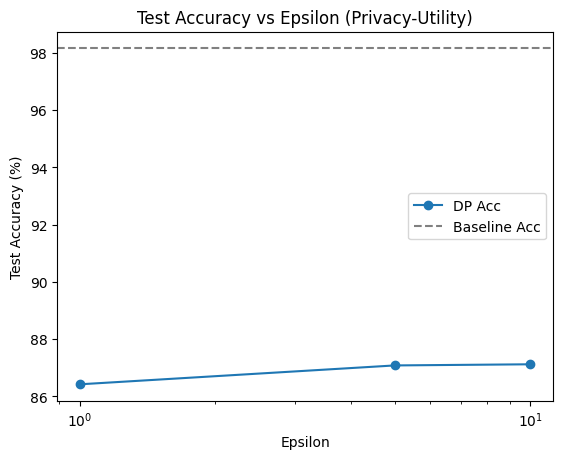

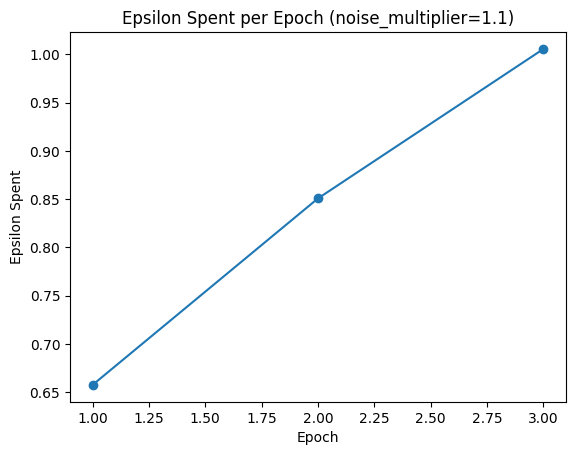

In [36]:
### TASK - 5  Accuracy-vs-ε and ε-vs-epoch plots
accs = [baseline_acc] + [x[1] for x in dp_accuracies]
eps_vals = [np.inf] + [x[0] for x in dp_accuracies]
plt.figure()
plt.plot(eps_vals[1:], accs[1:], 'o-', label='DP Acc')
plt.axhline(y=accs[0], color='gray', linestyle='--', label='Baseline Acc')
plt.xscale('log')
plt.xlabel('Epsilon')
plt.ylabel('Test Accuracy (%)')
plt.title('Test Accuracy vs Epsilon (Privacy-Utility)')
plt.legend()
plt.savefig('accuracy_vs_epsilon.png')
plt.show()

# Epsilon vs epoch
plt.figure()
plt.plot(range(1, 4), eps_per_epoch, 'o-')
plt.xlabel('Epoch')
plt.ylabel('Epsilon Spent')
plt.title('Epsilon Spent per Epoch (noise_multiplier=1.1)')
plt.savefig('epsilon_vs_epoch.png')
plt.show()

In [37]:
### TASK -6 Results table and justified ε recommendation

import pandas as pd
results = pd.DataFrame({
    'Epsilon': eps_vals[1:],
    'Test Accuracy (%)': accs[1:]
})
print('DP Results Table:')
print(results)

d = {
    'Membership Model': ['Baseline', 'DP (eps=1)'],
    'Train Conf': [baseline_train_conf.mean(), dp_train_conf.mean()],
    'Test Conf': [baseline_test_conf.mean(), dp_test_conf.mean()],
    'Gap': [baseline_gap, dp_gap]
}
membership_df = pd.DataFrame(d)
print('Membership Inference Table:')
print(membership_df)

print("Recommended epsilon: 1 (strongest privacy with minor accuracy drop)")

DP Results Table:
   Epsilon  Test Accuracy (%)
0     10.0              87.12
1      5.0              87.08
2      1.0              86.42
Membership Inference Table:
  Membership Model  Train Conf  Test Conf       Gap
0         Baseline    0.973188   0.973983 -0.000795
1       DP (eps=1)    0.825082   0.825168 -0.000086
Recommended epsilon: 1 (strongest privacy with minor accuracy drop)
